In [ ]:
!pip install torch torchvision torchaudio
!pip install scikit-learn seaborn tqdm matplotlib


In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation


/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
SOURCE = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
TARGET = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled/dummy"
TEST   = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

In [ ]:
!python attention_dann_mobilenetv2.py \
  --source-dir "$SOURCE" \
  --target-dir "$TARGET" \
  --test-dir "$TEST" \
  --out-dir /content/drive/MyDrive/Colab\ Results/DANN_TADA \
  --epochs 30 \
  --iters-per-epoch 300 \
  --batch-size 16 \
  --lambda-val 1.0 \
  --gamma 0.1 \
  --lr 1e-4 \
  --use-tada \
  --device cuda


Loading datasets...
Building model...
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth
100% 13.6M/13.6M [00:00<00:00, 249MB/s]
Training DANN (+ TADA=True)...
DANN+TADA Train Ep 1/30: 100% 300/300 [18:20<00:00,  3.67s/it, cls=1.22, dom_global=0.55, dom_local=0.638, ent=1.88, loss=2.6]
DANN+TADA Train Ep 2/30: 100% 300/300 [16:57<00:00,  3.39s/it, cls=1.01, dom_global=0.696, dom_local=0.661, ent=1.47, loss=2.51]
DANN+TADA Train Ep 3/30: 100% 300/300 [16:45<00:00,  3.35s/it, cls=0.575, dom_global=0.721, dom_local=0.675, ent=1.4, loss=2.11]
DANN+TADA Train Ep 4/30: 100% 300/300 [16:54<00:00,  3.38s/it, cls=0.719, dom_global=0.688, dom_local=0.667, ent=1.39, loss=2.21]
DANN+TADA Train Ep 5/30: 100% 300/300 [16:53<00:00,  3.38s/it, cls=0.86, dom_global=0.705, dom_local=0.677, ent=1.14, loss=2.36]
DANN+TADA Train Ep 6/30: 100% 300/300 [04:10<00:00,  1.20it/s, cls=0.331, dom_global=0.69, dom_local=0.646

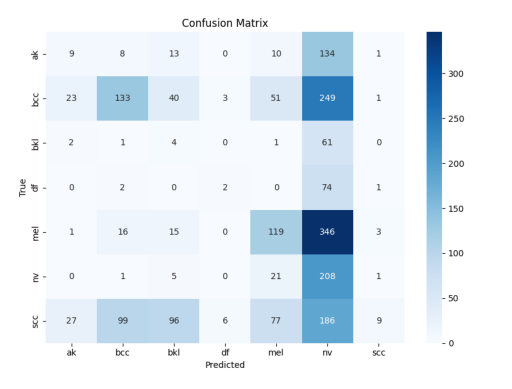

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

img = mpimg.imread('/content/drive/MyDrive/Colab Results/DANN_TADA/confusion_matrix.png')
plt.imshow(img)
plt.axis('off')
plt.show()


In [ ]:
import pandas as pd
report = pd.read_csv('/content/drive/MyDrive/Colab Results/DANN_TADA/classification_report.csv', index_col=0)
report


,precision,recall,f1-score,support
ak,0.145161,0.051429,0.075949,175.000000
bcc,0.511538,0.266000,0.350000,500.000000
bkl,0.023121,0.057971,0.033058,69.000000
df,0.181818,0.025316,0.044444,79.000000
mel,0.426523,0.238000,0.305520,500.000000
nv,0.165342,0.881356,0.278447,236.000000
scc,0.562500,0.018000,0.034884,500.000000
accuracy,0.235066,0.235066,0.235066,0.235066
macro avg,0.288001,0.219725,0.160329,2059.000000
weighted avg,0.403431,0.235066,0.208839,2059.000000


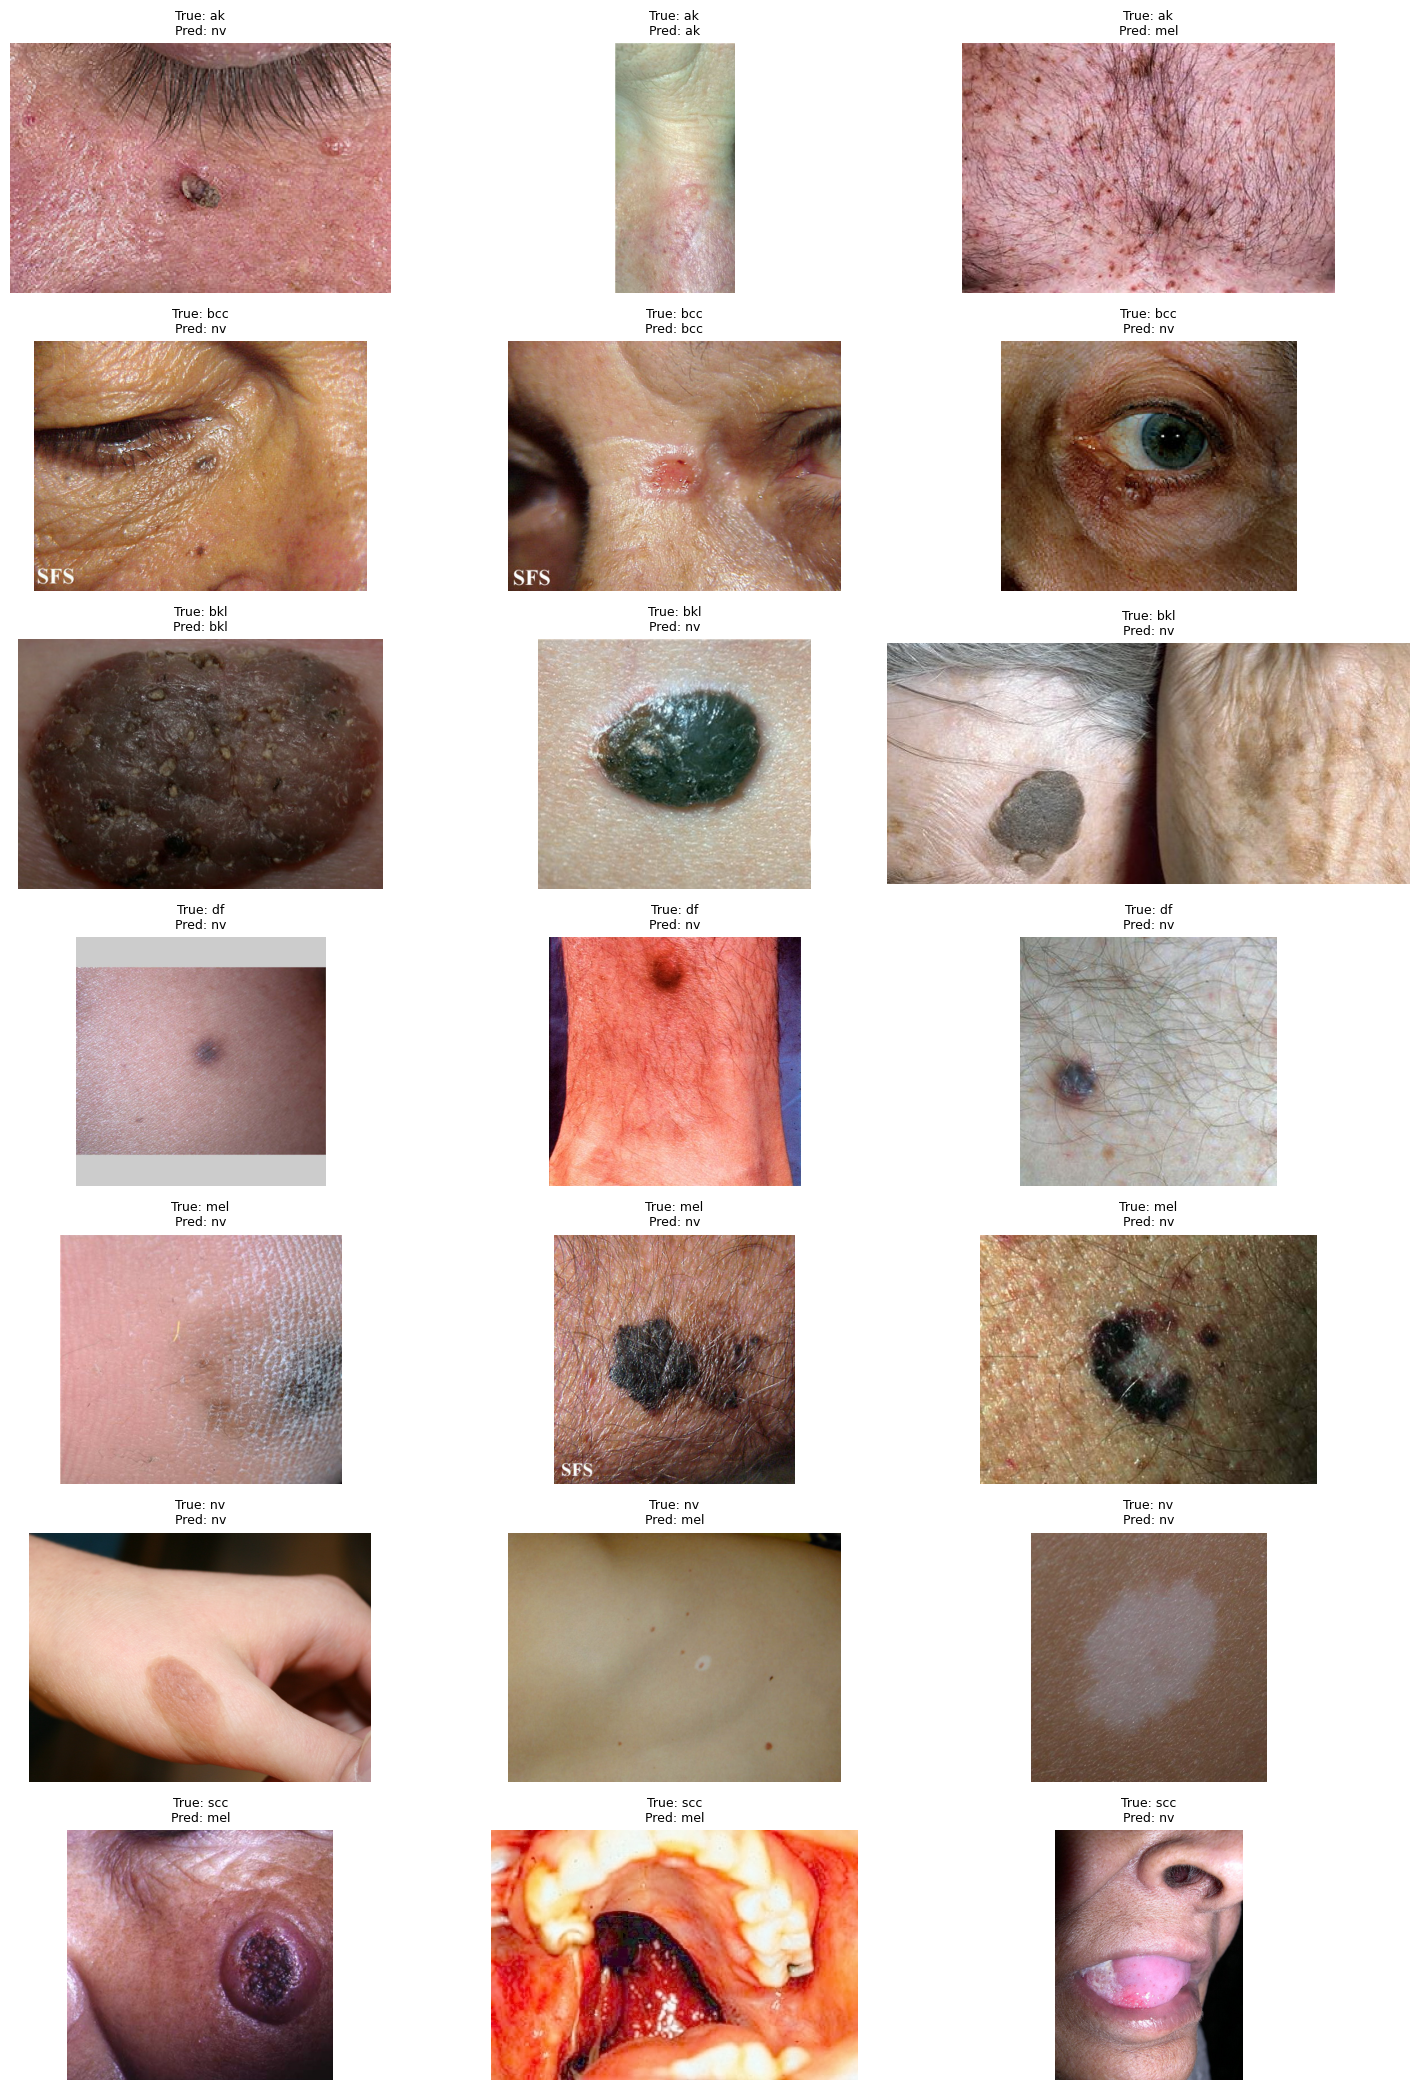

In [ ]:
import os
import torch
import random
import matplotlib.pyplot as plt
import numpy as np
from torchvision import transforms
from PIL import Image

TEST_DIR = TEST
device = 'cuda' if torch.cuda.is_available() else 'cpu'

from attention_dann_mobilenetv2 import get_mobilenetv2_encoder, ClassifierHead

encoder, feat_dim = get_mobilenetv2_encoder(pretrained=False)
classifier = ClassifierHead(feat_dim, num_classes=7)

checkpoint = torch.load('/content/drive/MyDrive/Colab Results/DANN_MOBILENETV2/full_model.pth', map_location=device)
encoder.load_state_dict(checkpoint['encoder'])
classifier.load_state_dict(checkpoint['classifier'])
encoder.to(device).eval()
classifier.to(device).eval()

tfm = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

class_dirs = [os.path.join(TEST_DIR, c) for c in os.listdir(TEST_DIR) if os.path.isdir(os.path.join(TEST_DIR, c))]
class_dirs.sort()
classes = [os.path.basename(c) for c in class_dirs]

num_samples = 3
plt.figure(figsize=(15, len(classes)*3))

for i, (cls, cls_dir) in enumerate(zip(classes, class_dirs)):
    images = random.sample([os.path.join(cls_dir, x) for x in os.listdir(cls_dir) if x.endswith(('.jpg','.png','.jpeg'))], num_samples)

    for j, img_path in enumerate(images):
        img = Image.open(img_path).convert("RGB")
        inp = tfm(img).unsqueeze(0).to(device)
        with torch.no_grad():
            fmap, pooled = encoder(inp)
            pred = classifier(pooled).argmax(1).item()

        plt.subplot(len(classes), num_samples, i*num_samples + j + 1)
        plt.imshow(img)
        plt.axis('off')
        plt.title(f"True: {cls}\nPred: {classes[pred]}", fontsize=9)

plt.tight_layout()
plt.show()
